# 02 — Feature Selection & Scaling

**Project:** Positionless NBA Player Archetypes · **Season:** 2025-26 · **Population:** 379 players with ≥ 500 minutes

The exploratory analysis (`01_EDA.ipynb`) ended with a set of decisions. This notebook turns them into the
**feature matrix** that every later stage (PCA, clustering, anomaly detection) will consume. The matrix decides what
"similar players" means: two players are close only if they are close *on the features chosen here*, scaled *the way
chosen here*. This is the step where basketball knowledge enters the model most directly.

| Decision inherited from EDA | How it is applied here |
|---|---|
| Use only the 379 players with ≥ 500 minutes | Load `data/processed/nba_2025_26_mp500.csv` |
| Describe **style**, not quality or volume | Only rate / share features; no per-game, totals, efficiency or impact metrics |
| Missing values are structural (0 attempts) | Exclude make-% columns; engineer features that are defined for every player |
| One representative per redundant group | Select features, then **verify with VIF** (§3) |
| Zone shares sum to 1 (compositional) | Merge zones so the set is no longer perfectly collinear (§2–3) |
| 13 of 23 candidate features have \|skew\| > 1 | Compare three scalers and choose on evidence (§4–5) |

**Outputs** (§6): the raw feature table and two scaled versions, `PowerTransformer` for PCA and clustering and
`StandardScaler` for anomaly detection and as a sensitivity check, each with player metadata attached.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import skew, kurtosis, spearmanr
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler, PowerTransformer, QuantileTransformer
from sklearn.neighbors import NearestNeighbors

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 80)
sns.set_theme(style='whitegrid', context='notebook')

DATA = Path('../data') if Path('../data').exists() else Path('data')
POS_ORDER = ['PG', 'SG', 'SF', 'PF', 'C']

---
## 1. Load the Filtered Population

**Goal.** Load the 379-player table exported at the end of the EDA and confirm it is the expected population.

**Why it matters.** Re-applying the minutes filter here could silently drift (a different threshold, a different
source file). Loading the exported file guarantees that the feature matrix describes exactly the players analysed in
the EDA. The table also carries the `pos_played` column (most-played position from play-by-play data), which will be
kept as metadata for validation.

**What to look for.** 379 rows, minimum minutes ≥ 500, one row per player.

In [2]:
nba = pd.read_csv(DATA / 'processed' / 'nba_2025_26_mp500.csv')
print('shape:', nba.shape)
print('min minutes:', nba['mp'].min(), '| unique players:', nba['player_id'].is_unique)
nba['pos'].value_counts().loc[POS_ORDER].to_frame('players').T

shape: (379, 128)
min minutes: 500 | unique players: True


pos,PG,SG,SF,PF,C
players,68,101,68,74,68


---
## 2. Feature Engineering & Selection

**Goal.** Define a compact set of features that describes **how a player is used and plays**, covering every major
dimension of a role, each concept exactly once.

**Design principles**
1. **Rates, not volumes.** Every feature is a percentage of opportunities (possessions, shots, rebounds available), so
   a 15-minute backup and a 35-minute starter with the same role look alike.
2. **Style, not quality.** Shooting percentages, plus/minus and impact metrics are excluded. A rim-running centre who
   finishes at 70% and one who finishes at 58% fill the *same role*; including efficiency would sort players by talent.
   Efficiency will instead be used *after* clustering to describe each archetype.
3. **Defined for every player.** No feature may be undefined for a non-shooter (the structural-missingness lesson from
   the EDA).
4. **One feature per concept.** Redundant pairs (|r| ≥ 0.8 in the EDA) contribute one representative.

### Engineered features

Three features are constructed rather than taken directly from the source tables:

| Feature | Formula | Why it is built this way |
|---|---|---|
| `rim_share` | `percent_fga_from_x0_3_range` | Renamed for readability: share of shots taken within 3 ft of the basket (lay-ups, dunks, tip-ins) |
| `mid_share` | share of FGA from 10–16 ft **+** 16 ft to the 3-point line | Merges the two mid-range zones into one "mid-range scorer" signal, which also breaks the zones' sum-to-1 constraint (§3) |
| `corner3_rate` | `x3p_ar × percent_corner_3s_of_3pa` | Share of **all** shots that are corner threes. The raw corner share is undefined for non-shooters and noisy for players with only a few threes (a centre who took 1 three, from the corner, has a 100% corner share). Multiplying by 3PA rate makes it 0 for non-shooters and small for low-volume shooters, so it is defined for everyone and only large for genuine corner specialists |

The 3–10 ft zone (floaters, hooks, short pull-ups) is deliberately left out: with 3PA rate, rim share and mid-range
share known, it equals `1 − (the other three)`, so it adds no information and would recreate the perfect collinearity.

In [3]:
X_src = nba.copy()
X_src['rim_share'] = X_src['percent_fga_from_x0_3_range']
X_src['mid_share'] = X_src['percent_fga_from_x10_16_range'] + X_src['percent_fga_from_x16_3p_range']
X_src['corner3_rate'] = X_src['x3p_ar'] * X_src['percent_corner_3s_of_3pa'].fillna(0)   # 0 attempts -> 0 corner threes

FEATURES = {
    # shot diet: where does the player shoot from?
    'x3p_ar':                  ('Shot diet',  '3PA rate: share of FGA that are threes'),
    'corner3_rate':            ('Shot diet',  'Share of FGA that are corner threes'),
    'mid_share':               ('Shot diet',  'Share of FGA from 10 ft to the 3-point line'),
    'rim_share':               ('Shot diet',  'Share of FGA within 3 ft'),
    'f_tr':                    ('Shot diet',  'Free-throw rate: FTA per FGA'),
    # creation: how much does the offense run through the player?
    'usg_percent':             ('Creation',   'Usage: % of team plays finished while on court'),
    'ast_percent':             ('Creation',   '% of teammate FGs assisted while on court'),
    'tov_percent':             ('Creation',   'Turnovers per 100 plays used'),
    'percent_assisted_x2p_fg': ('Creation',   '% of made 2s that were assisted (low = self-created)'),
    # rebounding
    'orb_percent':             ('Rebounding', '% of available offensive rebounds grabbed'),
    'drb_percent':             ('Rebounding', '% of available defensive rebounds grabbed'),
    # defensive activity
    'blk_percent':             ('Defense',    '% of opponent 2PA blocked'),
    'stl_percent':             ('Defense',    '% of opponent possessions ending in a steal'),
}
FEAT = list(FEATURES)
X = X_src[FEAT].copy()

pd.DataFrame(FEATURES, index=['group', 'meaning']).T.assign(
    median=X.median().round(3), min=X.min().round(3), max=X.max().round(3), missing=X.isna().sum())

,group,meaning,median,min,max,missing
x3p_ar,Shot diet,3PA rate: share of FGA that are threes,0.440,0.000,0.958,0
corner3_rate,Shot diet,Share of FGA that are corner threes,0.104,0.000,0.453,0
mid_share,Shot diet,Share of FGA from 10 ft to the 3-point line,0.100,0.000,0.579,0
rim_share,Shot diet,Share of FGA within 3 ft,0.216,0.008,0.922,0
f_tr,Shot diet,Free-throw rate: FTA per FGA,0.240,0.031,1.109,0
usg_percent,Creation,Usage: % of team plays finished while on court,18.600,8.500,38.100,0
ast_percent,Creation,% of teammate FGs assisted while on court,12.900,2.300,50.300,0
tov_percent,Creation,Turnovers per 100 plays used,12.000,4.700,25.800,0
percent_assisted_x2p_fg,Creation,% of made 2s that were assisted (low = self-created),0.578,0.114,0.922,0
orb_percent,Rebounding,% of available offensive rebounds grabbed,4.000,0.600,23.900,0


**Goal.** Sanity-check the engineered `corner3_rate` against what basketball knowledge predicts.

**What to look for.** The players at the top should be recognisable **"3-and-D" role players**: wings and forwards
whose offensive job is to stand in the corner and space the floor. If the top of the list were full of low-volume
centres, the feature would be measuring noise.

In [4]:
cmp = X_src[['player', 'pos', 'x3pa', 'x3p_ar', 'percent_corner_3s_of_3pa', 'corner3_rate']]
print('Top 8 by engineered corner3_rate:')
display(cmp.nlargest(8, 'corner3_rate').round(3))
print('Top 8 by raw corner share of 3PA (for comparison):')
display(cmp.nlargest(8, 'percent_corner_3s_of_3pa').round(3))

Top 8 by engineered corner3_rate:


,player,pos,x3pa,x3p_ar,percent_corner_3s_of_3pa,corner3_rate
128,Josh Green,SG,138.0,0.762,0.594,0.453
26,Nicolas Batum,PF,228.0,0.958,0.434,0.416
338,Jarred Vanderbilt,PF,99.0,0.413,0.909,0.375
272,Taurean Prince,SF,140.0,0.733,0.486,0.356
137,Gary Harris,SG,68.0,0.654,0.544,0.356
249,Josh Okogie,SG,161.0,0.548,0.646,0.354
180,Spencer Jones,SF,144.0,0.550,0.611,0.336
105,Rasheer Fleming,PF,130.0,0.605,0.546,0.330


Top 8 by raw corner share of 3PA (for comparison):


,player,pos,x3pa,x3p_ar,percent_corner_3s_of_3pa,corner3_rate
369,Mark Williams,C,1.0,0.002,1.000,0.002
338,Jarred Vanderbilt,PF,99.0,0.413,0.909,0.375
30,Adem Bona,C,6.0,0.027,0.833,0.022
371,Robert Williams,C,23.0,0.092,0.826,0.076
89,Andre Drummond,C,90.0,0.267,0.800,0.214
48,Dylan Cardwell,C,4.0,0.022,0.750,0.016
21,Dominick Barlow,PF,82.0,0.206,0.744,0.153
9,Kyle Anderson,SF,11.0,0.054,0.727,0.039


### Findings: Feature set
- **13 features in four role dimensions:** shot diet (5), creation (4), rebounding (2), defensive activity (2).
  **No missing values in any of them**, so no imputation is needed anywhere in the pipeline.
- The engineered `corner3_rate` behaves as intended. Its top players are the classic corner specialists (Josh Green,
  Nicolas Batum, Jarred Vanderbilt, Taurean Prince, Gary Harris, Josh Okogie). The **raw** corner share, by contrast,
  is topped by centres with a handful of attempts (Mark Williams: 1 three, 100% from the corner).
- **Known limitation: offense is over-represented** (9 of 13 features). Box-score data measures offense much better
  than defense: there are no public per-player rim-deterrence or matchup metrics in this dataset. Defensive roles
  will therefore be distinguished mostly through blocks, steals and rebounding. The PCA notebook will show how much
  variance each dimension actually carries.

---
## 3. Redundancy Check: Correlation & Variance Inflation Factor (VIF)

**Goal.** Confirm that the selected set no longer contains near-duplicates, using two complementary checks.

1. **Pairwise correlation**, which catches two features that move together.
2. **Variance Inflation Factor (VIF)**, which catches a feature that is *a combination of several others*. Pairwise
   correlation can miss this. For each feature *j*, regress it on all other features and compute

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

   VIF = 1 means the feature is unrelated to the rest; **VIF > 10** is the usual sign of serious redundancy; VIF → ∞
   means the feature is an *exact* linear combination of the others. (It can be computed in one step as the diagonal
   of the inverse correlation matrix.)

**Why it matters here.** The shot-zone shares are the textbook case that pairwise correlation misses: the five zones
always **sum to 1**, so each one is exactly determined by the other four, even though no single pair is perfectly
correlated. In clustering this means the shot-location concept is counted several times in the distance; in PCA it
produces a component with zero variance.

**What to look for.** VIF values for the *naive* set (all five zones, using `x3p_ar` as the 3-point zone) versus the
selected set.

In [5]:
def vif(frame):
    inv = np.linalg.pinv(np.corrcoef(frame.values, rowvar=False))
    return pd.Series(np.diag(inv), index=frame.columns)

zones = ['percent_fga_from_x0_3_range', 'percent_fga_from_x3_10_range',
         'percent_fga_from_x10_16_range', 'percent_fga_from_x16_3p_range', 'x3p_ar']
print('zone shares sum to: min %.3f, max %.3f' % tuple(X_src[zones].sum(axis=1).agg(['min', 'max'])))

naive = X_src[[f for f in FEAT if f not in ('rim_share', 'mid_share')]
              + ['percent_fga_from_x0_3_range', 'percent_fga_from_x3_10_range',
                 'percent_fga_from_x10_16_range', 'percent_fga_from_x16_3p_range']]
vif_table = pd.concat({'VIF naive (all 5 zones)': vif(naive).round(1),
                       'VIF selected (13 features)': vif(X).round(1)}, axis=1)
vif_table.sort_values('VIF naive (all 5 zones)', ascending=False)

zone shares sum to: min 0.998, max 1.005


,VIF naive (all 5 zones),VIF selected (13 features)
x3p_ar,88082.4,7.7
percent_fga_from_x0_3_range,54930.7,NaN
percent_fga_from_x3_10_range,18664.0,NaN
percent_fga_from_x10_16_range,7342.7,NaN
percent_fga_from_x16_3p_range,3815.1,NaN
orb_percent,4.9,4.8
ast_percent,3.2,3.2
usg_percent,3.2,3.2
corner3_rate,3.1,3.1
drb_percent,2.6,2.6


**Goal.** Visual confirmation with a correlation heatmap of the 13 selected features.

**What to look for.** No off-diagonal value near ±1. Moderate correlations (0.6–0.8) are expected and acceptable:
they reflect real basketball structure (bigs rebound, block shots and shoot near the rim), which is exactly what PCA is
meant to summarise. The aim is to remove *duplicate measurements*, not *related skills*.

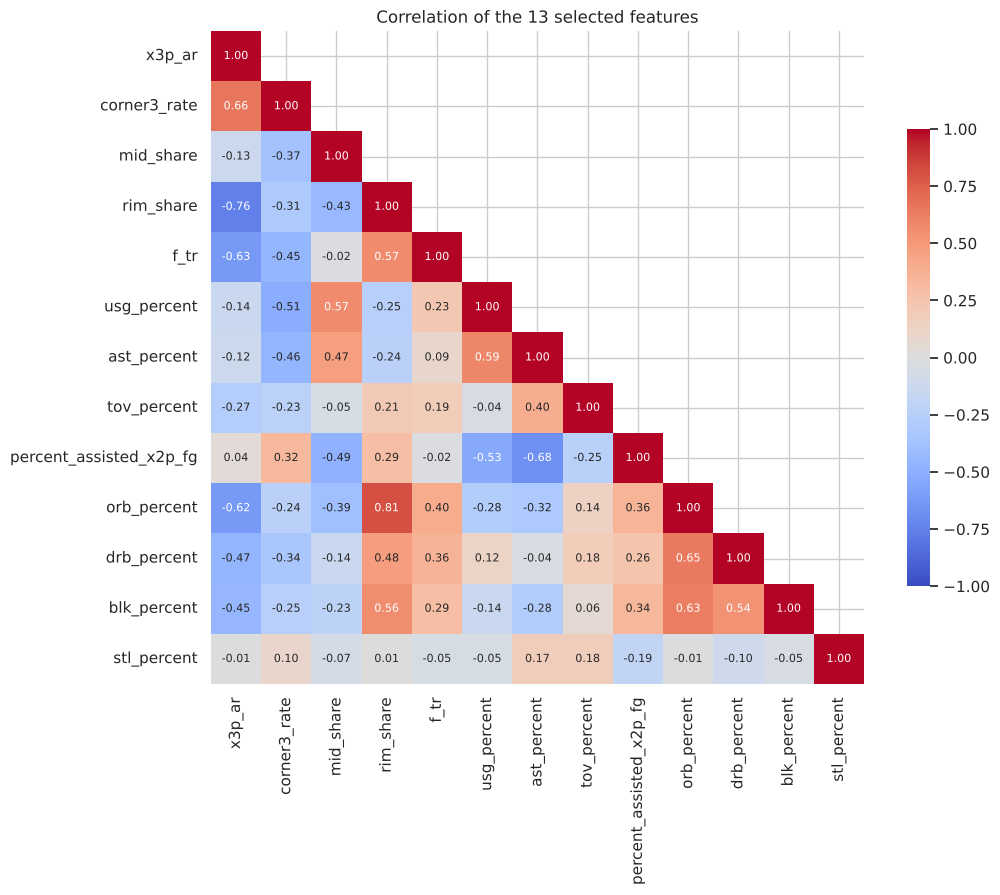

largest |r|:
rim_share    orb_percent                0.81
x3p_ar       rim_share                  0.76
ast_percent  percent_assisted_x2p_fg    0.68
x3p_ar       corner3_rate               0.66
orb_percent  drb_percent                0.65
x3p_ar       f_tr                       0.63


In [6]:
corr = X.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt='.2f',
            annot_kws={'size': 8}, cmap='coolwarm', vmin=-1, vmax=1, square=True, cbar_kws={'shrink': 0.7})
plt.title('Correlation of the 13 selected features')
plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1)).stack()
print('largest |r|:'); print(pairs.abs().sort_values(ascending=False).head(6).round(2).to_string())

### Findings: Redundancy
- With all five zone shares, VIF reaches the tens of thousands: the matrix is **perfectly collinear**, exactly as the
  sum-to-1 constraint predicts.
- After merging the mid-range zones and leaving the 3–10 ft zone implicit, **every VIF is below 10** (the highest are
  rim share ≈ 8.8 and 3PA rate ≈ 7.7, which naturally trade off against each other).
- The strongest remaining pair is rim share ↔ ORB% (r ≈ 0.81). The two are related but describe different actions
  (where a player shoots vs. crashing the offensive glass), and both are central to the "interior big" role, so both are kept.

---
## 4. Comparing Three Scaling Strategies

**Goal.** Put all 13 features on a common scale and choose the transform that gives the most faithful **distance
geometry** for clustering.

**Why scaling is unavoidable.** The raw features use different units: FTr runs to about 1.1, USG% to about 38,
ORB% to about 24. Without scaling, Euclidean distance would be dominated by whichever features have the largest
numeric range, an accident of units rather than a basketball judgement.

**The three candidates**

| Scaler | What it does | Strength | Risk |
|---|---|---|---|
| `StandardScaler` | (x − mean) / std | Simple; preserves the shape and relative gaps exactly | Long tails survive: a few specialists sit 5–7 std from the mean and dominate distances |
| `PowerTransformer` (Yeo-Johnson) | Fits a power transform per feature to make it as normal as possible, then standardises | Pulls in tails while keeping the order *and* the relative spacing of most players | Compresses genuine extremes, which matters for anomaly detection |
| `QuantileTransformer` (normal output) | Replaces each value by its rank, then maps ranks onto a normal curve | Fully robust to outliers; forces exactly normal marginals | Throws away the size of gaps (only ranks survive); ties (many identical zeros) get piled onto one artificial value |

**What to look for.** For each scaler: the remaining skewness and kurtosis, the most extreme value (max \|z\|), and
how much of the total spread comes from the most extreme 5% of players.

In [7]:
scalers = {
    'Standard': StandardScaler(),
    'Power (Yeo-Johnson)': PowerTransformer(method='yeo-johnson', standardize=True),
    'Quantile (normal)': QuantileTransformer(n_quantiles=len(X), output_distribution='normal', random_state=0),
}
scaled = {name: pd.DataFrame(s.fit_transform(X), columns=FEAT, index=X.index) for name, s in scalers.items()}

def summary(Z):
    sq = (Z ** 2).sum(axis=1)                       # each player's squared distance from the centre
    top = sq.sort_values(ascending=False).head(int(round(0.05 * len(Z))))
    return {'mean |skew|': Z.apply(skew).abs().mean(),
            'mean excess kurtosis': Z.apply(kurtosis).mean(),
            'max |z|': Z.abs().values.max(),
            'feature with max |z|': Z.abs().max().idxmax(),
            'share of spread from top 5% players': top.sum() / sq.sum()}

pd.DataFrame({name: summary(Z) for name, Z in scaled.items()}).T.round(3)

,mean |skew|,mean excess kurtosis,max |z|,feature with max |z|,share of spread from top 5% players
Standard,1.025861,1.561433,6.74862,f_tr,0.172143
Power (Yeo-Johnson),0.035079,-0.385708,3.443258,f_tr,0.128006
Quantile (normal),0.285815,2.990953,5.199338,x3p_ar,0.227411


**Goal.** Per-feature detail of the same comparison: the skewness left in each feature after each transform.

**What to look for.** Under `StandardScaler` the skew is identical to the raw data (it is a linear transform, so the
shape cannot change). The question is how close the other two get to 0, and whether any feature resists.

In [8]:
per_feat = pd.concat({name: Z.apply(skew) for name, Z in scaled.items()}, axis=1).round(2)
per_feat.sort_values('Standard', key=abs, ascending=False)

,Standard,Power (Yeo-Johnson),Quantile (normal)
blk_percent,1.74,0.05,-0.23
orb_percent,1.64,0.03,0.01
rim_share,1.47,0.07,-0.00
f_tr,1.35,0.01,-0.00
mid_share,1.27,0.11,-0.62
ast_percent,1.22,0.00,-0.00
drb_percent,0.94,0.01,-0.00
stl_percent,0.90,0.00,0.01
corner3_rate,0.84,0.07,-1.52
tov_percent,0.67,0.01,-0.00


**Goal.** See the effect of each transform on four representative features: two long-tailed specialist stats
(AST%, BLK%), the bimodal 3PA rate, and the zero-heavy engineered `corner3_rate`.

**What to look for.**
- **Top row (Standard):** same shape as the raw data, with long right tails reaching 4–5 std.
- **Middle row (Power):** tails pulled in, roughly bell-shaped, but the *spike of non-shooters* in 3PA rate stays
  visibly separate. Real structure is preserved.
- **Bottom row (Quantile):** perfectly smooth bells, except that tied values (players with exactly 0) are stacked
  on a single artificial extreme value (a separate bar at −5.2).

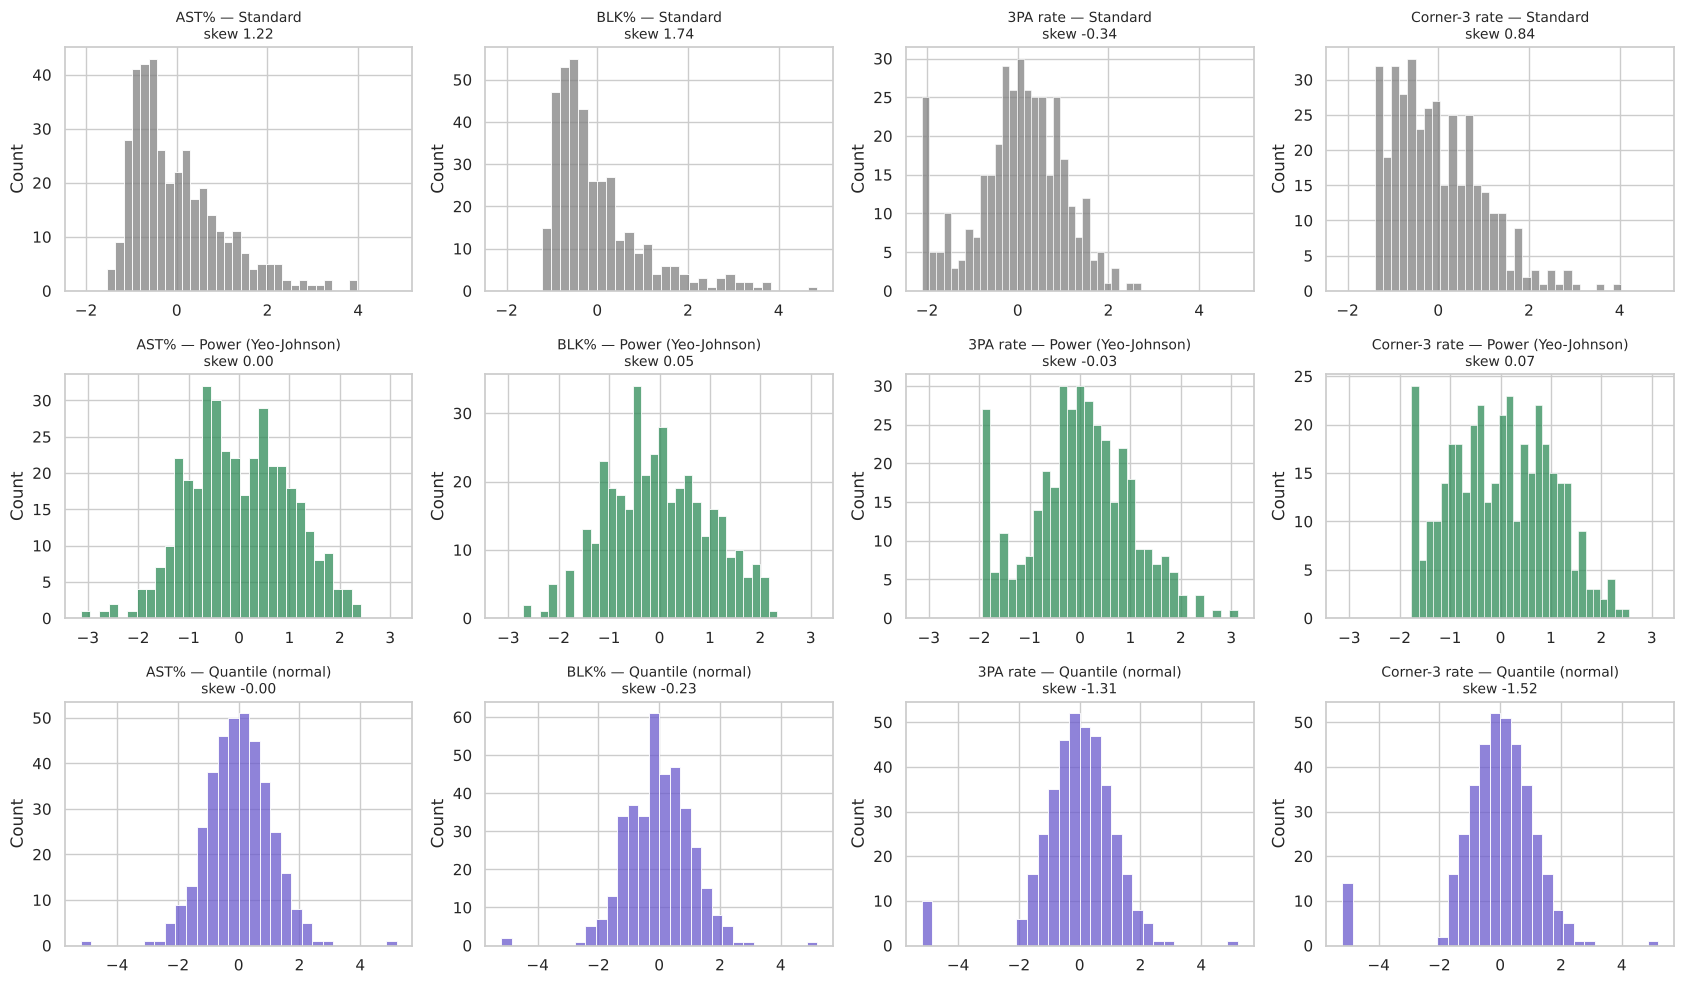

In [9]:
show = {'ast_percent': 'AST%', 'blk_percent': 'BLK%', 'x3p_ar': '3PA rate', 'corner3_rate': 'Corner-3 rate'}
colors = {'Standard': 'grey', 'Power (Yeo-Johnson)': 'seagreen', 'Quantile (normal)': 'slateblue'}
fig, ax = plt.subplots(3, 4, figsize=(17, 10), sharex='row')
for i, (name, Z) in enumerate(scaled.items()):
    for j, (col, label) in enumerate(show.items()):
        sns.histplot(Z[col], bins=30, ax=ax[i, j], color=colors[name])
        ax[i, j].set_title(f'{label} — {name}\nskew {skew(Z[col]):.2f}', fontsize=10)
        ax[i, j].set_xlabel('')
plt.tight_layout(); plt.show()

---
## 5. Does the Choice Change Who Is "Similar"?

Summary statistics describe each feature on its own. Clustering, however, depends on **distances between players**.
This section measures how much the three scalers agree on the geometry itself.

### 5a. Agreement of distances and nearest neighbours

**Goal.** Quantify how similar the three "player spaces" are.

**Method.**
- **Distance agreement:** compute all 71,631 pairwise player distances in each space and take the Spearman rank
  correlation between spaces. 1.0 means the scalers order every pair of players identically.
- **Neighbour agreement:** for every player, find the 10 nearest neighbours in each space and measure the average
  overlap. 1.0 means identical neighbourhoods. Neighbourhoods are what k-means, hierarchical clustering and LOF
  actually operate on.

**What to look for.** High agreement means the clusters will be robust to the scaling choice. Low agreement for one
scaler means its results should be interpreted with care.

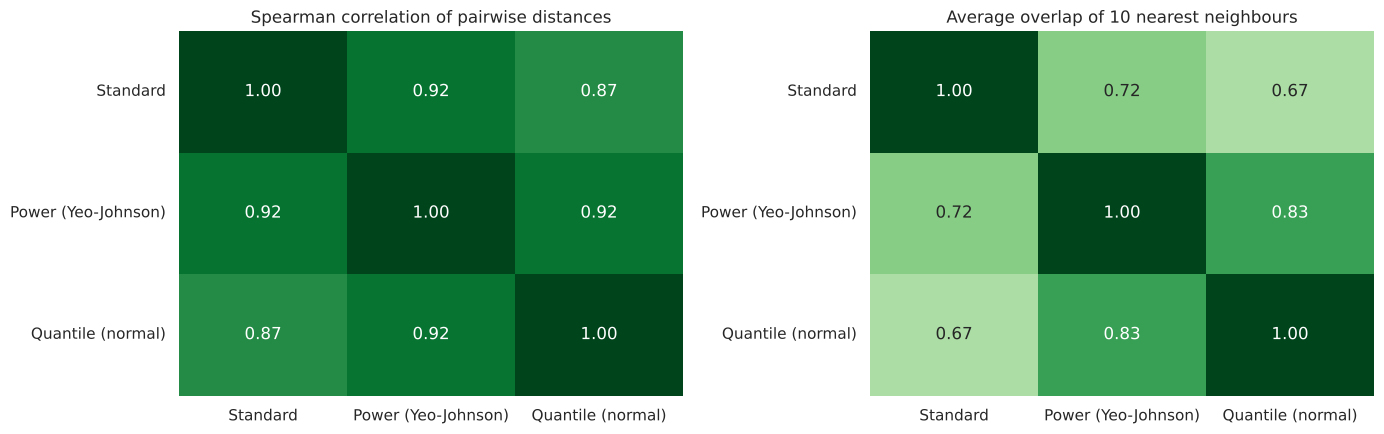

In [10]:
names = list(scaled)
dists = {n: pdist(scaled[n].values) for n in names}
knn = {n: NearestNeighbors(n_neighbors=11).fit(scaled[n].values).kneighbors(scaled[n].values)[1][:, 1:]
       for n in names}

dist_agree = pd.DataFrame(index=names, columns=names, dtype=float)
knn_agree = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        dist_agree.loc[a, b] = spearmanr(dists[a], dists[b])[0]
        knn_agree.loc[a, b] = np.mean([len(set(x) & set(y)) / 10 for x, y in zip(knn[a], knn[b])])

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, (m, title) in zip(ax, [(dist_agree, 'Spearman correlation of pairwise distances'),
                              (knn_agree, 'Average overlap of 10 nearest neighbours')]):
    sns.heatmap(m.astype(float), annot=True, fmt='.2f', cmap='Greens', vmin=0.5, vmax=1, cbar=False, ax=a)
    a.set_title(title)
plt.tight_layout(); plt.show()

### 5b. Face validity: nearest neighbours of well-known players

**Goal.** A qualitative check that the feature space captures basketball reality: list the three most similar
players for a set of well-known players with very different roles.

**Why it matters.** Statistics can look healthy while the space is meaningless. If a hub centre's nearest neighbours
were spot-up shooters, something would be wrong in the features or the scaling, however good the skewness numbers.

**What to look for.** Neighbours that a basketball fan would recognise as playing a *similar role*, regardless of
listed position or talent level, and the cases where the scalers disagree.

In [11]:
probe = ['Nikola Jokić', 'Giannis Antetokounmpo', 'Shai Gilgeous-Alexander', 'Stephen Curry',
         'Rudy Gobert', 'Victor Wembanyama', 'Draymond Green', 'Josh Hart']
rows = {}
for p in probe:
    i = X_src.index[X_src['player'] == p][0]
    rows[(p, X_src.loc[i, 'pos'])] = {n: ', '.join(X_src.loc[knn[n][i][:3], 'player']) for n in names}
pd.DataFrame(rows).T.rename_axis(['player', 'listed pos'])

,,Standard,Power (Yeo-Johnson),Quantile (normal)
player,listed pos,,,
Nikola Jokić,C,"Jalen Johnson, Josh Giddey, Alperen Şengün","Jalen Johnson, Alperen Şengün, Giannis Antetokounmpo","Jalen Johnson, Giannis Antetokounmpo, Cade Cunningham"
Giannis Antetokounmpo,PF,"Nikola Jokić, Alperen Şengün, Deni Avdija","Nikola Jokić, Alperen Şengün, Karl-Anthony Towns","Alperen Şengün, Karl-Anthony Towns, Paolo Banchero"
Shai Gilgeous-Alexander,PG,"Devin Booker, Jaylen Brown, Jalen Williams","Anthony Edwards, Tyrese Maxey, Jalen Williams","Anthony Edwards, Donovan Mitchell, Ja Morant"
Stephen Curry,PG,"Brandon Miller, Donovan Mitchell, Keyonte George","Keyonte George, Donovan Mitchell, Malik Monk","Keyonte George, Donovan Mitchell, Norman Powell"
Rudy Gobert,C,"Daniel Gafford, Moussa Diabaté, Goga Bitadze","Daniel Gafford, Moussa Diabaté, Steven Adams","Moussa Diabaté, Ryan Kalkbrenner, Goga Bitadze"
Victor Wembanyama,C,"Chet Holmgren, Alex Sarr, Anthony Davis","Anthony Davis, Alex Sarr, Evan Mobley","Anthony Davis, Chet Holmgren, Alex Sarr"
Draymond Green,PF,"Lonzo Ball, Josh Hart, Gui Santos","Nikola Jović, Jaylin Williams, Josh Hart","Nikola Jović, Josh Hart, Gui Santos"
Josh Hart,SF,"Jarace Walker, Gui Santos, Kyle Filipowski","Jarace Walker, Kyle Kuzma, Kyle Filipowski","Jarace Walker, Kyle Filipowski, Kenrich Williams"


### Findings: Scaling choice
- **`StandardScaler` leaves the problem in place:** mean |skew| ≈ 1.0, a player 6.7 std from the centre (on
  free-throw rate), and the most extreme 5% of players account for about 17% of the total spread.
- **`PowerTransformer` gives the best-behaved space:** mean |skew| ≈ 0.04, no player beyond 3.4 std, and the top 5%
  account for about 13% of the spread, without discarding the size of the gaps between players.
- **`QuantileTransformer` is worse than it looks.** Most of its marginals are perfect bells, but its kurtosis (≈ 3.0)
  and max |z| (5.2) are far *higher* than the power transform's, the top-5% share is the highest of the three
  (≈ 23%), and `corner3_rate` / `x3p_ar` keep a strong left skew (−1.5 / −1.3). The cause is ties: the 10 players
  with exactly zero threes (and the 14 with zero corner threes) are all mapped to the *same* artificial value of
  −5.2. That creates a block of fake outliers.
- **The geometry is fairly robust.** Pairwise-distance rankings agree strongly across scalers (Spearman 0.87–0.92).
  Neighbourhoods move more: on average about 7 of each player's 10 nearest neighbours are shared between the Standard
  and Power spaces. Clusters are therefore unlikely to change completely with the scaler, but individual borderline
  players may move, so this will be tested explicitly in the clustering notebook.
- **Face validity is strong under the power transform.** Jokić ↔ Johnson / Şengün / Antetokounmpo (hub forwards and
  bigs who run the offense); SGA ↔ Edwards / Maxey / J. Williams (high-usage, self-creating guards and wings);
  Curry ↔ George / Mitchell / Monk (pull-up three-point guards); Gobert ↔ Gafford / Diabaté / Adams (rim-running,
  offensive-rebounding centres); Wembanyama ↔ Davis / Sarr / Mobley (shot-blocking bigs who also step out);
  Draymond Green ↔ Jović / Jaylin Williams / Hart (connector forwards). Neighbours cross listed positions freely,
  which is exactly the point.

**Decision**

| Use | Scaled version | Reason |
|---|---|---|
| PCA, k-means, hierarchical clustering, GMM | **PowerTransformer (Yeo-Johnson)** | Most balanced geometry; GMM additionally assumes roughly Gaussian components |
| Sensitivity check for clustering | StandardScaler | Shows whether archetypes depend on the transform |
| Anomaly detection (Isolation Forest, LOF) | StandardScaler | Keeps genuine extremes extreme; the power transform deliberately compresses them |
| — | ~~QuantileTransformer~~ | Discards gap sizes and creates artificial extremes from ties |

---
## 6. Export

**Goal.** Save three aligned tables (same rows, same order) so later notebooks can load them directly:

| File | Content | Used by |
|---|---|---|
| `features_raw.csv` | metadata + 13 unscaled features | describing clusters in real units (e.g. "this archetype takes 62% of shots from three") |
| `features_power.csv` | metadata + 13 Yeo-Johnson-scaled features | PCA, clustering |
| `features_standard.csv` | metadata + 13 standardised features | anomaly detection, sensitivity checks |

**Metadata kept alongside (never used as model input):** identifiers, listed position (`pos`), most-played position
(`pos_played`) and the play-by-play position shares for validation, plus minutes and age for context.

**Why fit the scaler on all 379 players?** This is unsupervised learning on a fixed, complete population: there is
no test set and no future data to protect, so fitting on the full population is the correct choice and causes no
leakage.

In [12]:
META = ['player_id', 'player', 'team', 'pos', 'pos_played', 'age', 'g', 'mp',
        'pg_percent', 'sg_percent', 'sf_percent', 'pf_percent', 'c_percent']
out = DATA / 'processed'
tables = {'features_raw.csv': X,
          'features_power.csv': scaled['Power (Yeo-Johnson)'],
          'features_standard.csv': scaled['Standard']}
for fname, Z in tables.items():
    full = pd.concat([X_src[META], Z], axis=1)
    assert full[FEAT].notna().all().all() and len(full) == len(nba)
    full.to_csv(out / fname, index=False)
    print(f'saved {out / fname}  {full.shape}')

lam = pd.Series(scalers['Power (Yeo-Johnson)'].lambdas_, index=FEAT).round(3)
print('\nfitted Yeo-Johnson lambdas (1 = no reshaping, <1 = compresses a right tail, >1 = compresses a left tail):')
print(lam.to_string())

saved ../data/processed/features_raw.csv  (379, 26)
saved ../data/processed/features_power.csv  (379, 26)
saved ../data/processed/features_standard.csv  (379, 26)

fitted Yeo-Johnson lambdas (1 = no reshaping, <1 = compresses a right tail, >1 = compresses a left tail):
x3p_ar                     1.834
corner3_rate              -3.702
mid_share                 -4.851
rim_share                 -3.418
f_tr                      -2.225
usg_percent                0.036
ast_percent               -0.068
tov_percent                0.244
percent_assisted_x2p_fg    2.293
orb_percent               -0.275
drb_percent               -0.205
blk_percent               -0.554
stl_percent               -0.392


---
## Summary

| Step | Result |
|---|---|
| Population | 379 players (≥ 500 minutes), loaded from the EDA export |
| Feature set | **13 style features** in four dimensions: shot diet (5), creation (4), rebounding (2), defense (2) |
| Engineered features | `rim_share`, `mid_share` (merged mid-range zones), `corner3_rate` (corner threes as a share of all FGA) |
| Missing values | **None**: every feature is defined for every player, so no imputation |
| Redundancy | Naive zone set perfectly collinear (VIF in the tens of thousands) → selected set **max VIF ≈ 8.8** |
| Scaling | **PowerTransformer** for PCA / clustering, **StandardScaler** for anomaly detection and sensitivity; QuantileTransformer rejected |
| Face validity | Nearest neighbours group players by role across listed positions (Jokić–Şengün, Gobert–Gafford, SGA–Edwards) |

**Next: `03_PCA.ipynb`.** Scree plot and cumulative explained variance, component loadings (expected axes:
interior ↔ perimeter, on-ball creation ↔ off-ball role), and the 2-D projection of all players coloured by listed
and most-played position.